# 11 · Ajuste de hiperparámetros de la fusión mínima con LightGBM

El ajuste de DeBERTa no encontró nada mejor que su configuración original. Queda el otro componente del promedio: la
**fusión mínima**, es decir, las 7 features manuales más la similitud coseno con el texto fuente (`cos_sim`), con
LightGBM. Es el mejor modelo individual del proyecto (MCRMSE 0.576), pero sus hiperparámetros se fijaron de
antemano. Como cada entrenamiento tarda menos de un segundo, aquí sí es posible una búsqueda sistemática con Optuna.
Al final se recalcula el promedio 50/50 con DeBERTa usando el modelo ajustado.

**Validación anidada:** ajustar hiperparámetros mirando el error del prompt de validación sería hacer trampa. Por eso
hay dos niveles de Leave-One-Prompt-Out:

```
Fold externo (4 veces): se aparta 1 prompt para evaluar.
    Fold interno (3 veces): con los 3 prompts restantes, Optuna prueba combinaciones; cada una se entrena con 2
                            prompts y se mide en el tercero.
    La mejor combinación se entrena con los 3 prompts y predice el prompt apartado.
```

El prompt apartado nunca participa en la elección de hiperparámetros, así que el MCRMSE final se puede comparar
directamente con el 0.576 de 08.

## 1. Datos y features

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from IPython.display import display
from lightgbm import LGBMRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import LeaveOneGroupOut

PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "src").is_dir() and (path / "notebooks").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_csv_files
from src.evaluation import regression_metrics
from src.features import manual_features

INTERIM_DATA_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
for directory in [PROCESSED_DATA_DIR, TABLES_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

datasets = load_csv_files(INTERIM_DATA_DIR, ["summaries_train_clean.csv", "prompts_train_clean.csv"])
summaries: pd.DataFrame = datasets["summaries_train_clean"]
prompts: pd.DataFrame = datasets["prompts_train_clean"]

TARGETS: list[str] = ["content", "wording"]
y: np.ndarray = summaries[TARGETS].to_numpy()
groups: np.ndarray = summaries["prompt_id"].to_numpy()
PROMPT_TITLES: dict[str, str] = prompts.set_index("prompt_id")["prompt_title"].to_dict()
print("Resúmenes:", summaries.shape, "| Prompts:", prompts.shape)

Resúmenes: (7165, 5) | Prompts: (4, 4)


In [2]:
def load_spacy_embeddings(name: str, texts: list[str]) -> np.ndarray:
    # Reutiliza los embeddings que guardó 08; si no existen, los calcula igual que 08.
    path = PROCESSED_DATA_DIR / f"08_embeddings_{name}_spacy.npy"
    if path.is_file():
        embeddings = np.load(path)
        if embeddings.shape[0] == len(texts):
            return embeddings
    import spacy
    nlp = spacy.load("en_core_web_md", exclude=["tagger", "parser", "ner", "lemmatizer", "attribute_ruler", "senter"])
    embeddings = np.vstack([doc.vector for doc in nlp.pipe(texts, batch_size=256)])
    np.save(path, embeddings)
    return embeddings


features: pd.DataFrame = manual_features(summaries, prompts)
emb_summaries = load_spacy_embeddings("summaries", summaries["text"].tolist())
emb_prompts = load_spacy_embeddings("prompts", prompts["prompt_text"].tolist())
prompt_position = {prompt_id: i for i, prompt_id in enumerate(prompts["prompt_id"])}
emb_prompt_per_row = emb_prompts[[prompt_position[prompt_id] for prompt_id in summaries["prompt_id"]]]
features["cos_sim"] = (emb_summaries * emb_prompt_per_row).sum(axis=1) / (
    np.linalg.norm(emb_summaries, axis=1) * np.linalg.norm(emb_prompt_per_row, axis=1) + 1e-9)

X: np.ndarray = features.to_numpy()
assert np.isfinite(X).all()
print("Matriz de la fusión mínima:", X.shape, "| columnas:", features.columns.tolist())

Matriz de la fusión mínima: (7165, 8) | columnas: ['token_count', 'log_token_count', 'unique_token_count', 'lexical_diversity', 'palabras_prompt_overlap', 'bigramas_prompt_overlap', 'trigramas_prompt_overlap', 'cos_sim']


* Son exactamente las mismas 8 columnas que la fusión mínima de 08: 7 features manuales (`src.features`) y `cos_sim`
  con los embeddings de spaCy.
* Los embeddings se leen de la caché que dejó 08 (`data/processed/08_embeddings_*_spacy.npy`), así que no hace falta
  volver a cargar spaCy.

## 2. Punto de partida: los parámetros de 08

Antes de ajustar, se reproduce el resultado de 08 con sus mismos parámetros. Si las predicciones coinciden con las
guardadas en `08_oof_predictions.csv`, la comparación posterior es justa: lo único que cambia son los
hiperparámetros.

In [3]:
RANDOM_STATE: int = 42
PARAMS_08: dict = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=30,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.5)
FIXED: dict = dict(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)
FUSION_08: str = "Opción 1: Fusión mínima (A + cos_sim) + LightGBM"
logo = LeaveOneGroupOut()


def fit_predict(params: dict, X_train: np.ndarray, y_train: np.ndarray, X_valid: np.ndarray) -> np.ndarray:
    # Un LightGBM para un solo objetivo.
    return LGBMRegressor(**params, **FIXED).fit(X_train, y_train).predict(X_valid)


def lopo_oof(params_by_target: list[dict], X_: np.ndarray, y_: np.ndarray, groups_: np.ndarray) -> np.ndarray:
    # Predicciones out-of-fold con Leave-One-Prompt-Out, un modelo por objetivo.
    oof = np.zeros_like(y_, dtype=float)
    for train_idx, valid_idx in logo.split(X_, y_, groups_):
        for j, params in enumerate(params_by_target):
            oof[valid_idx, j] = fit_predict(params, X_[train_idx], y_[train_idx, j], X_[valid_idx])
    return oof


start = time.perf_counter()
oof_default = lopo_oof([PARAMS_08, PARAMS_08], X, y, groups)
print(f"Parámetros de 08: MCRMSE {regression_metrics(y, oof_default)['mcrmse']:.4f} "
      f"({time.perf_counter() - start:.1f} s)")

oof_08 = pd.read_csv(PROCESSED_DATA_DIR / "08_oof_predictions.csv")
saved = summaries[["student_id"]].merge(oof_08[oof_08["modelo"] == FUSION_08], on="student_id", validate="one_to_one")
assert np.allclose(saved[["pred_content", "pred_wording"]].to_numpy(), oof_default, atol=1e-6), \
    "No se reproduce 08: revise que las features sean las mismas."
print("Las predicciones coinciden con las de 08.")

Parámetros de 08: MCRMSE 0.5756 (2.6 s)


Las predicciones coinciden con las de 08.


* En 08 se usaba `MultiOutputRegressor(LGBMRegressor(...))`, que por dentro entrena **un LightGBM por objetivo**. Aquí
  se hace explícito con un modelo por objetivo, porque así cada objetivo puede tener sus propios hiperparámetros:
  `content` y `wording` no tienen por qué necesitar los mismos.
* `np.allclose(..., atol=1e-6)` comprueba que las predicciones son iguales salvo errores de redondeo.

## 3. Espacio de búsqueda

Optuna prueba combinaciones de hiperparámetros. Con un muestreador TPE, aprende de las pruebas anteriores qué zonas
del espacio dan menor error. Los rangos se fijaron de antemano alrededor de los valores de 08:

| Hiperparámetro | Rango | Qué controla |
|---|---|---|
| `n_estimators` | 100 – 1,500 | Número de árboles |
| `learning_rate` | 0.005 – 0.2 (escala log) | Cuánto corrige cada árbol; si es bajo, hacen falta más árboles |
| `num_leaves` | 4 – 64 | Complejidad de cada árbol |
| `min_child_samples` | 5 – 200 (escala log) | Resúmenes mínimos por hoja; un valor alto suaviza el modelo |
| `subsample` | 0.5 – 1.0 | Fracción de filas que ve cada árbol |
| `colsample_bytree` | 0.4 – 1.0 | Fracción de las 8 columnas que ve cada árbol |
| `reg_lambda`, `reg_alpha` | 0.001 – 10 (escala log) | Regularización L2 y L1 de las hojas |

In [4]:
N_TRIALS: int = 60   # combinaciones que prueba Optuna en cada búsqueda
optuna.logging.set_verbosity(optuna.logging.WARNING)


def suggest_params(trial: optuna.Trial) -> dict:
    return dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 1500, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 4, 64, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 200, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
    )


trial_frames: list[pd.DataFrame] = []   # historial de cada búsqueda: una fila por prueba


def tune(X_: np.ndarray, y_target: np.ndarray, groups_: np.ndarray, search: str, target: str) -> tuple[dict, float]:
    # Busca los hiperparámetros con menor RMSE out-of-fold, usando Leave-One-Prompt-Out dentro de los datos dados.
    def objective(trial: optuna.Trial) -> float:
        params = suggest_params(trial)
        oof = lopo_oof([params], X_, y_target[:, None], groups_)
        return root_mean_squared_error(y_target, oof[:, 0])

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.enqueue_trial({key: value for key, value in PARAMS_08.items() if key != "subsample_freq"}
                        | {"reg_lambda": 1e-3, "reg_alpha": 1e-3})
    study.optimize(objective, n_trials=N_TRIALS)
    trials = study.trials_dataframe(attrs=("number", "value", "params", "duration"))
    trial_frames.append(trials.assign(busqueda=search, objetivo=target))
    best = suggest_params(optuna.trial.FixedTrial(study.best_params))
    return best, study.best_value

**Sintaxis:**

* `trial.suggest_int(...)` / `suggest_float(...)` piden a Optuna un valor dentro del rango. Con `log=True` los valores
  se reparten en escala logarítmica: 0.005, 0.01 y 0.02 quedan igual de separados que 0.05, 0.1 y 0.2.
* `objective` devuelve el RMSE out-of-fold **interno**. Optuna busca la combinación que lo minimiza.
* `study.enqueue_trial(...)` hace que la primera prueba sean los parámetros de 08, con regularización casi nula. Así la
  búsqueda nunca termina peor, dentro de los datos internos, que el punto de partida.
* `TPESampler(seed=...)` hace la búsqueda reproducible.
* `study.trials_dataframe(...)` devuelve el historial de la búsqueda, con una fila por prueba: su número, el RMSE
  (`value`), los hiperparámetros probados (`params_*`) y cuánto tardó. Se guarda con el nombre de la búsqueda y el
  objetivo para graficar después cómo avanzó.
* `optuna.trial.FixedTrial(study.best_params)` vuelve a pasar los mejores valores por `suggest_params` para recuperar
  el diccionario completo, incluido `subsample_freq`.

## 4. Validación anidada

Para cada prompt apartado y cada objetivo se hace una búsqueda completa con los otros 3 prompts. Son
4 prompts × 2 objetivos = 8 búsquedas de 60 pruebas cada una.

In [5]:
oof_tuned = np.zeros_like(y, dtype=float)
param_rows: list[dict] = []
start = time.perf_counter()

for train_idx, valid_idx in logo.split(X, y, groups):
    prompt_id = groups[valid_idx][0]
    for j, target in enumerate(TARGETS):
        best, inner_rmse = tune(X[train_idx], y[train_idx, j], groups[train_idx],
                                search=f"Sin {PROMPT_TITLES[prompt_id]}", target=target)
        oof_tuned[valid_idx, j] = fit_predict(best, X[train_idx], y[train_idx, j], X[valid_idx])
        param_rows.append({"prompt_fuera": PROMPT_TITLES[prompt_id], "objetivo": target,
                           "rmse_interno": inner_rmse,
                           "rmse_prompt_fuera": root_mean_squared_error(y[valid_idx, j], oof_tuned[valid_idx, j]),
                           **best})
    print(f"{PROMPT_TITLES[prompt_id]:<28} listo ({time.perf_counter() - start:.0f} s)", flush=True)

params_df = pd.DataFrame(param_rows).drop(columns="subsample_freq")
display(params_df.round(4))
print(f"Validación anidada: MCRMSE {regression_metrics(y, oof_tuned)['mcrmse']:.4f} "
      f"(parámetros de 08: {regression_metrics(y, oof_default)['mcrmse']:.4f})")

On Tragedy                   listo (228 s)


Egyptian Social Structure    listo (494 s)


The Third Wave               listo (648 s)


Excerpt from The Jungle      listo (823 s)


,prompt_fuera,objetivo,rmse_interno,rmse_prompt_fuera,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,reg_alpha
0,On Tragedy,content,0.5044,0.4308,800,0.0106,8,36,0.9009,0.7038,0.2648,0.4482
1,On Tragedy,wording,0.7154,0.6050,450,0.0187,9,7,0.5475,0.4476,0.0064,0.0025
2,Egyptian Social Structure,content,0.4720,0.5096,900,0.0141,4,26,0.5767,0.9828,0.2068,2.7033
3,Egyptian Social Structure,wording,0.6385,0.7408,900,0.0053,12,42,0.8569,0.7137,0.0037,3.1538
4,The Third Wave,content,0.4762,0.5195,1050,0.0118,5,5,0.6464,0.5678,5.6270,0.0072
5,The Third Wave,wording,0.6238,0.8242,350,0.0217,6,21,0.8726,0.4585,0.0050,0.0224
6,Excerpt from The Jungle,content,0.4878,0.4664,750,0.0108,8,20,0.5568,0.9591,0.8784,0.2573
7,Excerpt from The Jungle,wording,0.7356,0.5493,100,0.0349,8,17,0.8122,0.4201,0.0083,0.0095


Validación anidada: MCRMSE 0.5734 (parámetros de 08: 0.5756)


* Cada fila es una búsqueda: los mejores hiperparámetros encontrados **sin** el prompt de esa fila, su RMSE interno y
  su RMSE en el prompt apartado.
* Si los valores elegidos se parecen entre filas del mismo objetivo, la búsqueda es estable. Si cambian mucho, el
  error es poco sensible a los hiperparámetros y la mejora probablemente sea pequeña.
* `rmse_interno` suele ser menor que `rmse_prompt_fuera`: el interno se eligió como el mínimo de 60 pruebas, así que
  es optimista. Por eso el número que se reporta es el del prompt apartado.

## 5. Hiperparámetros finales

La validación anidada **estima** cuánto rinde el procedimiento de ajuste. Para el modelo que se usaría en la
práctica, se repite la búsqueda una vez con los 4 prompts (Leave-One-Prompt-Out de 4 folds). Su RMSE interno es
optimista y no se usa para comparar modelos.

In [6]:
final_params: dict[str, dict] = {}
for j, target in enumerate(TARGETS):
    final_params[target], final_rmse = tune(X, y[:, j], groups, search="Final (4 prompts)", target=target)
    param_rows.append({"prompt_fuera": "(ninguno: final con los 4 prompts)", "objetivo": target,
                       "rmse_interno": final_rmse, "rmse_prompt_fuera": np.nan, **final_params[target]})
    print(target, json.dumps({key: round(value, 4) if isinstance(value, float) else value
                              for key, value in final_params[target].items()}))

params_df = pd.DataFrame(param_rows).drop(columns="subsample_freq")
params_df.to_csv(TABLES_DIR / "11_lgbm_tuning_params.csv", index=False)

content {"n_estimators": 500, "learning_rate": 0.018, "num_leaves": 7, "min_child_samples": 22, "subsample": 0.754, "subsample_freq": 1, "colsample_bytree": 0.8976, "reg_lambda": 5.241, "reg_alpha": 0.0295}


wording {"n_estimators": 300, "learning_rate": 0.0143, "num_leaves": 11, "min_child_samples": 18, "subsample": 0.6042, "subsample_freq": 1, "colsample_bytree": 0.4938, "reg_lambda": 0.9849, "reg_alpha": 0.0129}


### Cómo avanzó la búsqueda

Optuna no prueba combinaciones al azar: después de las primeras pruebas se concentra en las zonas que dieron menos
error. La gráfica muestra las 60 pruebas de la búsqueda final de cada objetivo y el mejor RMSE encontrado hasta cada
prueba.

Pruebas guardadas: 600 | búsquedas: 10


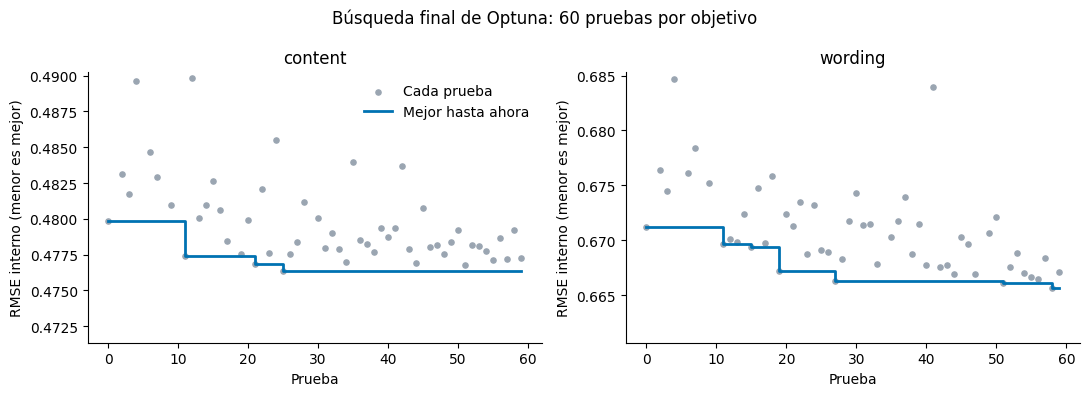

,primera_prueba,mejor,prueba_del_mejor
objetivo,,,
content,0.4798,0.4763,25
wording,0.6712,0.6657,58


In [7]:
trials_df = pd.concat(trial_frames, ignore_index=True)
trials_df["duration"] = trials_df["duration"].dt.total_seconds()
trials_df = trials_df.rename(columns={"number": "prueba", "value": "rmse_interno", "duration": "segundos"})
trials_df.columns = [column.removeprefix("params_") for column in trials_df.columns]
trials_df["mejor_hasta_ahora"] = trials_df.groupby(["busqueda", "objetivo"])["rmse_interno"].cummin()
trials_df.to_csv(TABLES_DIR / "11_optuna_trials.csv", index=False)
print("Pruebas guardadas:", len(trials_df), "| búsquedas:", trials_df.groupby(["busqueda", "objetivo"]).ngroups)

final_search = trials_df[trials_df["busqueda"] == "Final (4 prompts)"]
fig, axes = plt.subplots(1, 2, figsize=[11, 4], sharex=True)
for ax, target in zip(axes, TARGETS):
    rows = final_search[final_search["objetivo"] == target]
    ax.scatter(rows["prueba"], rows["rmse_interno"], s=14, color="#9aa5b1", label="Cada prueba")
    ax.step(rows["prueba"], rows["mejor_hasta_ahora"], where="post", color="#0072B2", linewidth=2,
            label="Mejor hasta ahora")
    ax.set(title=target, xlabel="Prueba", ylabel="RMSE interno (menor es mejor)",
           ylim=(rows["rmse_interno"].min() - 0.005, rows["rmse_interno"].quantile(0.9)))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.suptitle("Búsqueda final de Optuna: 60 pruebas por objetivo")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "11_optuna_history.png", dpi=150, bbox_inches="tight")
plt.show()

improvement = final_search.groupby("objetivo").agg(primera_prueba=("rmse_interno", "first"),
                                                   mejor=("rmse_interno", "min"),
                                                   prueba_del_mejor=("rmse_interno", "idxmin"))
improvement["prueba_del_mejor"] = final_search.loc[improvement["prueba_del_mejor"], "prueba"].to_numpy()
display(improvement.round(4))

* La prueba 0 son los parámetros de 08 (`enqueue_trial`), así que la primera fila de la tabla es el punto de partida.
* `cummin()` calcula el mínimo acumulado: el mejor RMSE encontrado hasta cada prueba.
* El eje y se corta en el percentil 90 para que las pocas pruebas muy malas no aplasten la curva.
* `11_optuna_trials.csv` guarda las 600 pruebas (10 búsquedas de 60): las 8 de la validación anidada y las 2 finales.

**Lectura.** La búsqueda mejora el punto de partida, pero poco: en `content`, el RMSE interno baja de 0.4798 (los
parámetros de 08) a 0.4763, y el mejor aparece en la prueba 25; en `wording`, de 0.6712 a 0.6657, en la prueba 58.
En las primeras pruebas, Optuna explora y aparecen combinaciones malas. Después las pruebas se concentran cerca del
mejor valor: es TPE aprovechando lo que ya aprendió. La curva escalonada se aplana pronto, señal de que el error es
poco sensible a los hiperparámetros, y por eso el ajuste completo apenas movió el resultado con prompts nuevos.

## 6. Resultados y nuevo promedio con DeBERTa

Se comparan, con los mismos resúmenes y la misma validación:

* la fusión mínima con los parámetros de 08 y con los ajustados (validación anidada);
* el promedio 50/50 con DeBERTa (09), antes y después del ajuste, si `09_deberta_oof_predictions.csv` está en
  `data/processed/`.

In [8]:
TUNED: str = "Fusión mínima + LightGBM ajustado (validación anidada)"
DEFAULT: str = "Fusión mínima + LightGBM (parámetros de 08)"
candidates: dict[str, np.ndarray] = {DEFAULT: oof_default, TUNED: oof_tuned}

OOF_09_PATH: Path = PROCESSED_DATA_DIR / "09_deberta_oof_predictions.csv"
if OOF_09_PATH.is_file():
    deberta = summaries[["student_id"]].merge(pd.read_csv(OOF_09_PATH), on="student_id", validate="one_to_one")
    p_deberta = deberta[["pred_content", "pred_wording"]].to_numpy()
    candidates["DeBERTa-v3-base (09)"] = p_deberta
    candidates["Promedio 50/50: DeBERTa + fusión (parámetros de 08)"] = 0.5 * p_deberta + 0.5 * oof_default
    candidates["Promedio 50/50: DeBERTa + fusión ajustada"] = 0.5 * p_deberta + 0.5 * oof_tuned
else:
    print(f"No se encontró {OOF_09_PATH.name}; se omite el promedio con DeBERTa.")

results = (pd.DataFrame([{"modelo": name, **regression_metrics(y, pred)} for name, pred in candidates.items()])
           .sort_values("mcrmse").reset_index(drop=True))
by_prompt = pd.DataFrame([
    {"modelo": name, "prompt_id": prompt_id, "prompt_title": PROMPT_TITLES[prompt_id],
     **regression_metrics(y[groups == prompt_id], pred[groups == prompt_id])}
    for name, pred in candidates.items() for prompt_id in np.unique(groups)
])
display(results[["modelo", "rmse_content", "r2_content", "rmse_wording", "r2_wording", "mcrmse"]].round(4))

pivot = by_prompt.pivot(index="modelo", columns="prompt_title", values="mcrmse").loc[results["modelo"]]
display(pivot.round(4))
difference = pivot.loc[TUNED] - pivot.loc[DEFAULT]
print("Ajustado menos parámetros de 08, por prompt (negativo = mejora):")
display(difference.round(4).to_frame("diferencia").T)
print(f"El ajuste mejora en {(difference < 0).sum()} de {len(difference)} prompts.")

results.to_csv(TABLES_DIR / "11_lgbm_tuning_results.csv", index=False)
by_prompt.to_csv(TABLES_DIR / "11_lgbm_tuning_by_prompt.csv", index=False)

,modelo,rmse_content,r2_content,rmse_wording,r2_wording,mcrmse
0,Promedio 50/50: DeBERTa + fusión (parámetros d...,0.4327,0.8280,0.6243,0.6368,0.5285
1,Promedio 50/50: DeBERTa + fusión ajustada,0.4327,0.8281,0.6256,0.6354,0.5291
2,Fusión mínima + LightGBM ajustado (validación ...,0.4777,0.7904,0.6690,0.5830,0.5734
3,Fusión mínima + LightGBM (parámetros de 08),0.4800,0.7884,0.6713,0.5801,0.5756
4,DeBERTa-v3-base (09),0.4616,0.8043,0.7397,0.4902,0.6007


prompt_title,Egyptian Social Structure,Excerpt from The Jungle,On Tragedy,The Third Wave
modelo,,,,
Promedio 50/50: DeBERTa + fusión (parámetros de 08),0.5748,0.4706,0.5134,0.5608
Promedio 50/50: DeBERTa + fusión ajustada,0.5772,0.4714,0.5123,0.5613
Fusión mínima + LightGBM ajustado (validación anidada),0.6252,0.5078,0.5179,0.6719
Fusión mínima + LightGBM (parámetros de 08),0.6254,0.5124,0.5224,0.6716
DeBERTa-v3-base (09),0.6338,0.5157,0.6253,0.6272


Ajustado menos parámetros de 08, por prompt (negativo = mejora):


prompt_title,Egyptian Social Structure,Excerpt from The Jungle,On Tragedy,The Third Wave
diferencia,-0.0003,-0.0045,-0.0045,0.0002


El ajuste mejora en 3 de 4 prompts.


* La resta por prompt es una **comparación pareada**: los dos modelos se evalúan en los mismos resúmenes. Una
  mejora que aparece en los 4 prompts es más creíble que una que viene de uno solo.
* El promedio 50/50 con la fusión ajustada sigue siendo honesto: el peso se fijó antes y las predicciones ajustadas
  vienen de la validación anidada.

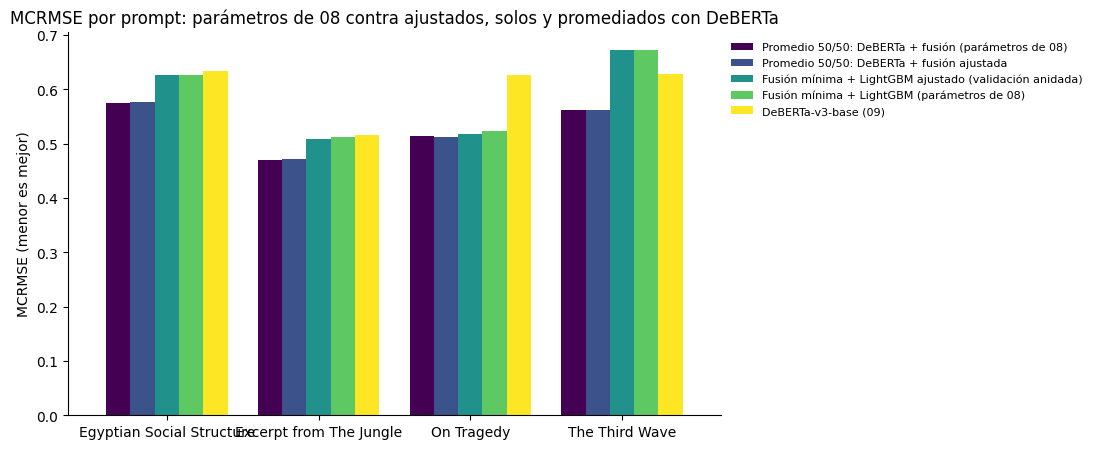

In [9]:
fig, ax = plt.subplots(figsize=[11, 4.6])
pivot.T.plot.bar(ax=ax, width=0.8, colormap="viridis")
ax.set(title="MCRMSE por prompt: parámetros de 08 contra ajustados, solos y promediados con DeBERTa",
       xlabel="", ylabel="MCRMSE (menor es mejor)")
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "11_lgbm_tuning_by_prompt.png", dpi=150, bbox_inches="tight")
plt.show()

oof_frames: list[pd.DataFrame] = []
for name in [TUNED, "Promedio 50/50: DeBERTa + fusión ajustada"]:
    if name not in candidates:
        continue
    rows = summaries[["student_id", "prompt_id", *TARGETS]].copy()
    rows["modelo"] = name
    for j, target in enumerate(TARGETS):
        rows[f"pred_{target}"] = candidates[name][:, j]
        rows[f"error_abs_{target}"] = np.abs(y[:, j] - candidates[name][:, j])
    oof_frames.append(rows)
pd.concat(oof_frames, ignore_index=True).to_csv(PROCESSED_DATA_DIR / "11_oof_predictions.csv", index=False)

* `11_oof_predictions.csv` tiene las mismas columnas que `08_oof_predictions.csv` y `09_deberta_oof_predictions.csv`,
  para que la comparación final pueda juntarlos.

## 7. Conclusiones

| Modelo (prompt no visto) | RMSE content | RMSE wording | MCRMSE |
|---|---|---|---|
| Fusión mínima + LightGBM, parámetros de 08 | 0.480 | 0.671 | 0.576 |
| Fusión mínima + LightGBM, ajustado (validación anidada) | 0.478 | 0.669 | **0.573** |
| Promedio 50/50: DeBERTa + fusión, parámetros de 08 | 0.433 | 0.624 | **0.529** |
| Promedio 50/50: DeBERTa + fusión ajustada | 0.433 | 0.626 | 0.529 |

1. **El ajuste casi no mejora: 0.5756 → 0.5734 (−0.002).** Mejora en 3 de los 4 prompts, pero en dos de ellos por
   menos de 0.005 y en los otros dos la diferencia es prácticamente cero (*Egyptian Social Structure* −0.0002, *The
   Third Wave* +0.0003). Es una mejora real pero muy pequeña.
2. **Los parámetros de 08 ya estaban cerca del óptimo.** La búsqueda los incluía como primera prueba y las
   combinaciones elegidas se parecen en lo esencial: árboles pequeños (4–12 hojas) y una tasa de aprendizaje baja.
3. **Los hiperparámetros elegidos cambian mucho entre folds** (por ejemplo, `n_estimators` va de 100 a 1,050 en
   `wording`). Muchas combinaciones distintas dan casi el mismo error: el error está limitado por la información de
   las 8 features, no por cómo se configura LightGBM.
4. **El promedio con DeBERTa no mejora** (0.5285 contra 0.5291). La pequeña ganancia de la fusión se pierde al
   promediar, porque el ajuste no cambia qué información aporta el modelo, solo afina sus predicciones.
5. **El RMSE interno no anticipa el del prompt nuevo.** Por ejemplo, en *The Third Wave* `wording` pasa de 0.62
   interno a 0.82 fuera. La dificultad del prompt nuevo pesa más que los hiperparámetros.

**En síntesis:** el ajuste de hiperparámetros con validación anidada confirma que LightGBM ya estaba bien
configurado (0.576 → 0.573). Para mejorar hacen falta **mejores entradas**, no mejores hiperparámetros: más
información sobre el texto (como el transformer) o mejores features. El modelo recomendado sigue siendo el promedio
50/50 de DeBERTa y la fusión mínima (MCRMSE 0.529). Para el modelo final se pueden usar los parámetros de 08 o los
ajustados de la sección 5; la diferencia no es significativa.
